# Recommender System Project

Author: Maria Khanina

Reviewer: Shani Gendelis

Description: Implementing Factorization Machine and using it to give movies recommendations for users of MovieLens.

Infinity Labs R&D AI #5

In [1]:
from typing import Callable, Literal

import duckdb
import matplotlib.pyplot as plt
import numpy as np
from numpy.typing import ArrayLike
import pandas as pd
import seaborn as sns
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import root_mean_squared_error, ndcg_score
from sklearn.model_selection import train_test_split, GridSearchCV, PredefinedSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.utils import check_X_y, check_array
from scipy.sparse import csr_array, issparse, spmatrix, sparray, vstack

from factorization_machine import mean_lowest_rating, ndcg_p_score, get_predicted_top, FactorizationMachine

## Factorization Machine

### Testing on Toy Dataset

In [2]:
def _predict_y_fm(X, w0, weights, factors):
    """Predict y using parameters and assumptions of Factorization Machine."""
    X_dot_factors = X @ factors
    X_dot_factors_squares = X ** 2 @ (factors ** 2)
    interactions = np.sum(X_dot_factors ** 2 - X_dot_factors_squares, axis=1) / 2
    linear_part = X @ weights
    return w0 + linear_part + interactions, X_dot_factors

In [3]:
rng = np.random.default_rng()
toy_shape = (1000, 10)
factors_num = 4
X = rng.normal(size=toy_shape)

intercept = -100
weights = np.ones(shape=(X.shape[1],))
factors = rng.normal(size=(X.shape[1], factors_num))

y = _predict_y_fm(X, intercept, weights, factors)[0]
y += rng.normal(scale=abs(np.mean(y) * 0.05))

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y)
X_val, X_test, y_val, y_test = train_test_split(X_test, y_test, train_size=0.5)

fm = FactorizationMachine(
    random_state=42, 
    batch_size=300,
    learn_rate=0.1,
    factors_num=20,
    metric="neg_rmse",
)

fm.fit(X_train, y_train, eval_set=(X_val, y_val))

In [5]:
fm.score(X_test, y_test)

-0.0006351001170137889

# Movies dataset

I had a MovieLens datasets of users rating movies and wanted to use factorization machine to recommend new movies to users based on the dataset.

Datasets I worked with:

- movies -- 3952 rows with different movies identified by id, with columns title (contains release year) and genres;

- ratings -- 1,000,209 records of 3706 users identified by id submitting an integer rating from 1 to 5 to movies identified by id.

## EDA

* MovieLens100k and MovieLens1M can't be used together -- users' ids don't match.
* Ratings and movies datasets have no missing values, but not all movies appear in ratings dataset.
* Records were added in different timestamps. We don't know when user actually saw the movie, only then grade is added to the dataset, so there is no point of using timestamp as a feature, but we must split data with respect to timestamp not to have leak of future records in the training set.
* Users and movies are encoded with their id -- must be one hot encoded so each user and each movie have their own parameters and factorization machine can learn specific movies and users.
* Because each user and each movie receive their own columns and model will learn users' preferences directly from the user id feature, other users' and as well movies' features may be not extracted. Nevertheless, possibly relevant features are:
    + release year extracted from movie's title
    + one hot encoded genres
    + one hot encoded user's occupation
    + one hot encoded user's gender
    + ordinally encoded user's age

In [6]:
with duckdb.connect("/home/maria-khanina/mkgit/movies_project/data/database.duckdb", read_only=True) as db_conn:
    ratings_df = db_conn.execute("""
        SELECT *
        FROM ratings
            INNER JOIN movies USING (movie_id)
            INNER JOIN users USING (user_id)
    """).df()


In [7]:
ratings_df.head()

,user_id,movie_id,rating,timestamp,title,genres,gender,age,occupation,zip_code
0,1,1193,5,978300760,One Flew Over the Cuckoo's Nest (1975),Drama,F,1,10,48067
1,1,661,3,978302109,James and the Giant Peach (1996),Animation|Children's|Musical,F,1,10,48067
2,1,914,3,978301968,My Fair Lady (1964),Musical|Romance,F,1,10,48067
3,1,3408,4,978300275,Erin Brockovich (2000),Drama,F,1,10,48067
4,1,2355,5,978824291,"Bug's Life, A (1998)",Animation|Children's|Comedy,F,1,10,48067


#### Timestamp:

timestamp -- number of seconds passed since some fixed moment in time. It represents the moment record was added to the database. Some records were added at the same moment in time for the same user.

In [8]:
groupby_user = ratings_df.groupby("user_id")
time_range = groupby_user["timestamp"].max() - groupby_user["timestamp"].min()
days_range = time_range / (60 * 60 * 24)

In [9]:
days_range.min(), days_range.max()

(np.float64(0.0012268518518518518), np.float64(1032.9605555555556))

In [10]:
(days_range > 180).sum()

np.int64(934)

Significant amount of users have more than half a year between grading different movies, we must take that inro account when splitting data on train and test -- each user's test records must be chronologically after train records.

Text(0, 0.5, 'Users amount')

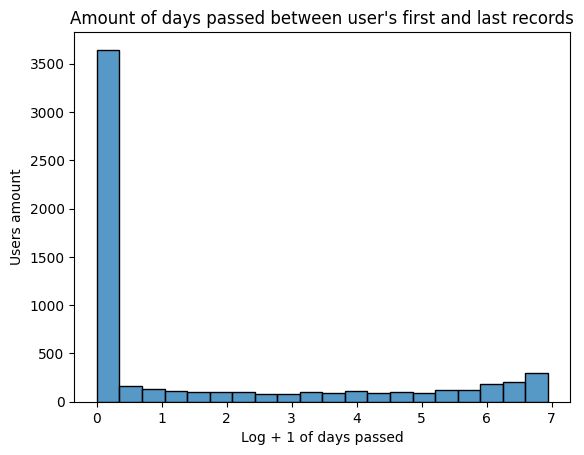

In [11]:
sns.histplot(np.log1p(days_range))
plt.title("Amount of days passed between user's first and last records")
plt.xlabel("Log + 1 of days passed")
plt.ylabel("Users amount")

#### Ratings:

In [12]:
ratings_df["rating"].value_counts().sort_index()

rating
1     56174
2    107557
3    261197
4    348971
5    226310
Name: count, dtype: int64

How many records we have about each user and each movie:

In [13]:
movies_per_user = ratings_df.groupby("user_id").size().describe()
users_per_movie = ratings_df.groupby("movie_id").size().describe()
pd.DataFrame({
    "Movies per user": movies_per_user,
    "Users per movie": users_per_movie
}, index=["mean", "std", "min", "25%", "50%", "75%", "max"])


,Movies per user,Users per movie
mean,165.597517,269.889099
std,192.747029,384.047838
min,20.000000,1.000000
25%,44.000000,33.000000
50%,96.000000,123.500000
75%,208.000000,350.000000
max,2314.000000,3428.000000


Both distributions are right-skewed, in the future records for movies with less than 5 ratings will be removed -- we don't have enough data to learn something about those movies.

## Temporal split on train, validation, test

In [14]:
def per_var_split_mask(
        df_sorted: pd.DataFrame,
        var: str,
        max_test_ratio=0.1,
        test_max_per_var=10,
):
    """
        Prepare splitting for given dataframe such as each unique value of var 
        has max_test_ratio ratio of records in test set capped at test_max_per_var.
    """
    per_var_count = df_sorted[var].map(df_sorted[var].value_counts())
    per_var_ranks = df_sorted.groupby(var).cumcount(ascending=False)
    per_var_test_size = np.minimum(test_max_per_var, max_test_ratio * per_var_count)
    per_var_test_size = np.maximum(per_var_test_size, 3)
    test_mask = per_var_ranks < per_var_test_size

    return test_mask

In [15]:
def per_var_temporal_split(
        X: pd.DataFrame,
        y: ArrayLike,
        var="user_id",
        time_col="timestamp",
        max_test_ratio=0.1,
        test_max_per_var=10,
) -> tuple[pd.DataFrame, pd.DataFrame, pd.Series, pd.Series]:
    """
        Split X and y to train and test such as for each value of var
        all test records have greater time_col values than train records,
        and each value of var receives max_test_ratio of records in test,
        capped at test_max_per_var.
    """
    sort_indices = X.sort_values(by=[var, time_col]).index
    X_sorted = X.loc[sort_indices]
    y_sorted = pd.Series(y, index=X.index).loc[sort_indices]
    test_mask = per_var_split_mask(X_sorted, var, max_test_ratio, test_max_per_var)
    return X_sorted[~test_mask], X_sorted[test_mask], y_sorted[~test_mask], y_sorted[test_mask]

In [16]:
X_train_all, X_test, y_train_all, y_test = per_var_temporal_split(
    X=ratings_df.drop(columns="rating"),
    y=ratings_df["rating"],
    var="user_id",
    time_col="timestamp",
    max_test_ratio=0.1,
    test_max_per_var=10,
)

Testing custom split:

In [17]:
X_train_all["user_id"].nunique(), X_test["user_id"].nunique()

(6040, 6040)

-- all users present both in train and test sets.

In [18]:
(X_train_all.groupby("user_id")["timestamp"].max() > X_test.groupby("user_id")["timestamp"].min()).sum()

np.int64(0)

-- for each user train records are not later than test records

In [19]:
X_test.groupby("user_id").size().describe()

count    6040.000000
mean        7.656788
std         2.774625
min         3.000000
25%         5.000000
50%        10.000000
75%        10.000000
max        10.000000
dtype: float64

In [20]:
X_train_all.groupby("user_id").size().describe()

count    6040.000000
mean      157.940728
std       191.219097
min        17.000000
25%        39.000000
50%        86.000000
75%       198.000000
max      2304.000000
dtype: float64

-- enough data to train and test for each user.

We will use 2 validation sets: one temporary to pass to model's fir method for deciding when to stop gradient descent, and one for comparing hyperparameters/models/different feature extractions methods.

In [21]:
X_train_big, X_outer_val, y_train_big, y_outer_val = per_var_temporal_split(
    X_train_all,
    y_train_all,
    var="user_id",
    time_col="timestamp",
    max_test_ratio=0.1,
    test_max_per_var=10,
)

In [22]:
X_train, X_val, y_train, y_val = per_var_temporal_split(
    X_train_big,
    y_train_big,
    var="user_id",
    time_col="timestamp",
    max_test_ratio=0.1,
    test_max_per_var=10,
)

In [23]:
X_train.shape[0] / ratings_df.shape[0]

0.8658250425661037

## Fitting, evaluating, comparing models.

For evaluating model's performance, 3 metrics will be used:

* root mean square error between real and predicted grades user gave to a movie
* mean user's lowest grade of a movie they would see in recommendations if recommendations are made from movies users rated
* mean user's normalized discounted cumulative gain -- how well predicted ratings rank real movies user rated.

### Random predictions

In [24]:
rng = np.random.default_rng()
random_preds = rng.choice(
    np.arange(1, 6), 
    size=y_outer_val.shape[0],
    replace=True,
)

ndcg_p_score(
    y_outer_val, 
    random_preds,
    X_outer_val["user_id"], 
    p=5
)

np.float64(0.7514551822118276)

NDCG is already pretty high!

In [25]:
root_mean_squared_error(y_outer_val, random_preds)

1.8894194685390022

In [26]:
mean_lowest_rating(y_outer_val, random_preds, X_outer_val["user_id"], 5)

np.float64(2.6399006622516556)

### Base model for comparison: predicting user's grade for a movie as average movie's rating on train set.

In [27]:
df_train = pd.concat((X_train_big, y_train_big), axis="columns")
avg_total = df_train["rating"].mean()
avg_train_ratings = df_train.groupby("movie_id", as_index=False)["rating"].mean()
avg_train_ratings.columns = ["movie_id", "avg_movie_rating"]

In [28]:
df_outer_val = pd.merge(left=X_outer_val, right=avg_train_ratings, on="movie_id", how="left")
df_outer_val["avg_movie_rating"] = df_outer_val["avg_movie_rating"].fillna(avg_total)

In [29]:
root_mean_squared_error(y_outer_val, df_outer_val["avg_movie_rating"])

0.9918437064396192

In [30]:
mean_lowest_rating(
    true_ratings=y_outer_val,
    predicted_ratings=df_outer_val["avg_movie_rating"],
    users=df_outer_val["user_id"],
    recommend_num=5,
)

np.float64(2.815728476821192)

In [31]:
ndcg_p_score(
    y_outer_val,
    df_outer_val["avg_movie_rating"],
    df_outer_val["user_id"],
    p=5,
)

np.float64(0.8314571959873557)

### Factorization Machine with only encoded user_id and movie_id as features

In [32]:
all_users = np.sort(X_train["user_id"].unique())
all_movies = np.sort(X_train["movie_id"].unique())

If movie or user has less than 5 records on train set, we won't learn their weight and factors to avoid overfitting:

In [33]:
basic_transformer = ColumnTransformer(
    transformers=[
        (
            "encode_id",
            OneHotEncoder(
                categories=[all_users, all_movies],
                handle_unknown="ignore",
                min_frequency=5,
            ),
            ["user_id", "movie_id"],
        ),
    ],
    remainder="drop",
)

In [34]:
X_train_transformed = basic_transformer.fit_transform(X_train)
X_val_transformed = basic_transformer.transform(X_val)
X_outer_val_transformed = basic_transformer.transform(X_outer_val)

In [35]:
def fit_evaluate(
        metric: str, 
        factors_num: int = 20, 
        factors_penalty: float = 0,
        recommend_num: int = 5, 
):
    basic_fm = FactorizationMachine(
        verbose=True,
        metric=metric,
        tol=1e-4,
        factors_num=factors_num,
        factors_penalty=factors_penalty,
        recommend_num=recommend_num,
    )
    basic_fm.fit(
        X_train_transformed,
        y_train,
        eval_set=(X_val_transformed, y_val),
        users=X_val["user_id"],
    )
    
    val_predictions = basic_fm.predict(X_outer_val_transformed)
    y_pred_clipped = np.clip(val_predictions, 1, 5)
    return {
        "recommendations num": recommend_num,
        "target metric": metric,
        "factors num": factors_num,
        "factors penalty": factors_penalty,
        "last epoch": basic_fm.stop_epoch,
        "rmse": root_mean_squared_error(y_outer_val, y_pred_clipped),
        "mean_lowest_rating": mean_lowest_rating(y_outer_val, val_predictions, X_outer_val["user_id"], recommend_num),
        f"ndcg": ndcg_p_score(y_outer_val, val_predictions, X_outer_val["user_id"], recommend_num)
    }



We will use ndcg as target metric as it is commonly used metric that punishes model for both recommending worst movies and not recommending best movies.

(It was also tested that different target metrics (ndcg, mean lowest rating, rmse) show almost equal results in all metrics.)

Trying different number of factors, number of movies to recommend, adding regularization:

In [ ]:
factors_grid = [(10, 0), (30, 0), (30, 0.0001)]
scores = []

for p in [3, 4, 5]:
    for n_factors, factors_penalty in factors_grid:
        result = fit_evaluate(
            metric="ndcg", 
            factors_num=n_factors,
            factors_penalty=factors_penalty,
            recommend_num=p,
        )
        scores.append(result)

It was tested that with regularization 0.001 factors are almost zero.

In [209]:
pd.DataFrame(scores)

,recommendations num,target metric,factors num,factors penalty,last epoch,rmse,mean_lowest_rating,ndcg
0,3,ndcg,10,0.0000,136,0.889789,3.213411,0.809547
1,3,ndcg,30,0.0000,95,0.881127,3.227483,0.813938
2,3,ndcg,30,0.0001,79,0.930394,3.144868,0.788173
3,4,ndcg,10,0.0000,121,0.888736,3.009603,0.831195
4,4,ndcg,30,0.0000,84,0.879860,3.025993,0.835392
5,4,ndcg,30,0.0001,81,0.930235,2.952483,0.811443
6,5,ndcg,10,0.0000,144,0.889410,2.866887,0.848736
7,5,ndcg,30,0.0000,95,0.879221,2.881291,0.854212
8,5,ndcg,30,0.0001,29,0.942632,2.813742,0.831208


As it is expected, recommending more movies improves ndcg score but adds worse films to recommendations (so mean_lowest_rating drops). Regularization doesn't improve any score, and although there is no big difference between 10 or 30 factors, 30 produces better scores.

### Adding genres:

In [69]:
transformer_with_genres = ColumnTransformer(
    transformers=[
        (
            "extract_genres",
            CountVectorizer(
                input="content",
                tokenizer=lambda x:x.split("|"),
                binary=True,
            ),
            "genres"
        ),
        (
            "encode_id",
            OneHotEncoder(
                categories=[all_users, all_movies],
                handle_unknown="ignore",
                min_frequency=5,
            ),
            ["user_id", "movie_id"],
        ),
    ],
    remainder="drop",
)

In [ ]:
X_train_transformed = transformer_with_genres.fit_transform(X_train)
X_val_transformed = transformer_with_genres.transform(X_val)
X_outer_val_transformed = transformer_with_genres.transform(X_outer_val)

In [71]:
genres_results = fit_evaluate(
    metric="ndcg",
    factors_num=35,
)

Epoch 0, factors num 35, 
factors abs mean: 0.03288560419508475, 
weights abs mean: 0.033101454863858217, 
intercept 3.427839635059373,best validation ndcg score 0.832831878876166
Epoch 20, factors num 35, 
factors abs mean: 0.05371455584128426, 
weights abs mean: 0.04963203561628627, 
intercept 3.3028115899231896,best validation ndcg score 0.8391620984047722
Epoch 40, factors num 35, 
factors abs mean: 0.06255740782310602, 
weights abs mean: 0.05416001590066057, 
intercept 3.2652633603110606,best validation ndcg score 0.8417693743033126
Epoch 60, factors num 35, 
factors abs mean: 0.06968195262560278, 
weights abs mean: 0.057335025137966275, 
intercept 3.242483417437378,best validation ndcg score 0.8431943528881624
Epoch 0, factors num 35, 
factors abs mean: 0.03326824073982912, 
weights abs mean: 0.03320806223878377, 
intercept 3.4205308451230625,best validation ndcg score -inf
Epoch 20, factors num 35, 
factors abs mean: 0.05330528302889854, 
weights abs mean: 0.048995451253359336, 

In [213]:
genres_results

{'recommendations num': 5,
 'target metric': 'mean_lowest_per_user',
 'factors num': 35,
 'factors penalty': 0,
 'last epoch': 12,
 'rmse': 0.9161518451267161,
 'mean_lowest_rating': np.float64(2.818543046357616),
 'ndcg': np.float64(0.8371713725674677)}

Scores dropped significantly

### Factorization Machine with user's preferences added to features

In [26]:
class UserHistoryTransformer(TransformerMixin, BaseEstimator):
    def __init__(
            self, 
            user_col="user_id",
            item_col="movie_id",
            rating_max=5.0,
    ):
        self.user_col = user_col
        self.item_col = item_col
        self.rating_max = rating_max

    def fit(self, X, y):
        y_scaled = y / self.rating_max
        self._user_history = csr_array(
            (y_scaled, (X[self.user_col], X[self.item_col])),
        )
        return self
    
    def transform(self, X):
        users = X[self.user_col].values
        items = X[self.item_col].values
        
        X_history = self._user_history[users].copy()
        X_history[np.arange(len(X)), items] = 0
        X_history.eliminate_zeros()
        
        return X_history


#### Testing transformer works as expected:

In [27]:
X_transformed = UserHistoryTransformer().fit(X_train, y_train).transform(X_train)

In [28]:
row_idx = 239
user_id = X_train.iloc[row_idx]["user_id"]
movie_id = X_train.iloc[row_idx]["movie_id"]
actual_rating = y_train.iloc[row_idx] / 5.0
one_row = X_transformed[row_idx].toarray()
one_row

array([0., 0., 0., ..., 0., 0., 0.], shape=(3953,))

In [30]:
assert one_row[movie_id] == 0

In [31]:
favorite_movie = np.argmax(one_row == 1)
movie_rated_1 = np.argmax(one_row == 0.2)
assert ratings_df[(ratings_df["user_id"] == user_id) & (ratings_df["movie_id"] == favorite_movie)]["rating"].min() == 5
assert ratings_df[(ratings_df["user_id"] == user_id) & (ratings_df["movie_id"] == movie_rated_1)]["rating"].min() == 1

#### Training model:

In [32]:
transformer = ColumnTransformer(
    transformers=[
        ("extract_history", UserHistoryTransformer(), ["user_id", "movie_id"]),
        (
            "encode", 
            OneHotEncoder(
                categories=[all_users, all_movies],
                handle_unknown="ignore",
                min_frequency=5,
            ),
            ["user_id", "movie_id"],
        ),
    ],
    remainder="drop",
    verbose=True,
)

In [ ]:
X_train_transformed = transformer.fit_transform(X_train, y_train)
X_val_transformed = transformer.transform(X_val)
X_outer_val_transformed = transformer.transform(X_outer_val)

In [ ]:
history_results = fit_evaluate(
    metric="ndcg",
    factors_num=45,
)

In [35]:
history_results

{'recommendations num': 5,
 'target metric': 'ndcg',
 'factors num': 45,
 'factors penalty': 0,
 'last epoch': 146,
 'rmse': 0.9036647113715159,
 'mean_lowest_rating': np.float64(2.8549668874172185),
 'ndcg': np.float64(0.8435547707751595)}

Scores are similar to the base model ones.

## Test scores:

In the end, simple model with 30 factors and no regularization shows best results.

In [36]:
best_fm = FactorizationMachine(factors_num=30, max_epoch=95)

X_train_all_transformed = basic_transformer.fit_transform(X_train_all, y_train_all)
X_test_transformed = basic_transformer.transform(X_test)
best_fm.fit(X_train_all_transformed, y_train_all, users=X_train_all["user_id"])
test_pred = best_fm.predict(X_test_transformed)


In [37]:
ndcg_p_score(y_test, test_pred, X_test["user_id"])

np.float64(0.8512311096933669)

In [38]:
mean_lowest_rating(y_test, test_pred, X_test["user_id"], 5)

np.float64(2.860430463576159)

In [39]:
root_mean_squared_error(y_test, test_pred)

0.8928357820994504

## Exploring model recommendations for new users

Fitting model on all the existing data:

In [ ]:
fm = FactorizationMachine(factors_num=30, max_epoch=100)
X = ratings_df[["user_id", "movie_id"]]
X_transformed = basic_transformer.fit_transform(X)

fm.fit(
    X_transformed,
    ratings_df["rating"],
)


9999 -- user id that doesn't exist in dataset

In [86]:
new_user_df = pd.DataFrame({
    "user_id": 9999,
    "movie_id": ratings_df["movie_id"].unique(),
}).sort_values(by="movie_id")

In [87]:
encoded_new_user_df = basic_transformer.transform(new_user_df)
new_user_predictions = fm.predict(encoded_new_user_df)
avg_ratings = ratings_df.groupby("movie_id")["rating"].mean()

How predicted grades of movies from a new user differ from average movies ratings:

In [ ]:
root_mean_squared_error(avg_ratings, new_user_predictions)

0.5332038444328067

Relatively close

In [75]:
top_indices = np.argsort(new_user_predictions)[-5:][::-1]
recommended_ids = new_user_df.loc[top_indices, "movie_id"].values

Stats of movies that would be recommended to a new user:

In [79]:
ratings_df[ratings_df["movie_id"].isin(recommended_ids)].groupby("movie_id").agg({
    "rating": ["count", "mean"]
})

rating          
          count      mean
movie_id                 
282         215  3.223256
531         338  3.769231
561          13  3.615385
1649        189  3.851852
2253        440  2.563636

Most popular movies:

In [85]:
ratings_df.groupby("movie_id").agg({
    "rating": ["count", "mean"]
}).nlargest(n=10, columns=[("rating", "count")])

rating          
          count      mean
movie_id                 
2858       3428  4.317386
260        2991  4.453694
1196       2990  4.292977
1210       2883  4.022893
480        2672  3.763847
2028       2653  4.337354
589        2649  4.058513
2571       2590  4.315830
1270       2583  3.990321
593        2578  4.351823

Model doesn't work well on new users...